In [1]:
import tensorflow as tf
import numpy as np
from keras.callbacks import LambdaCallback
import matplotlib.pyplot as plt
import random

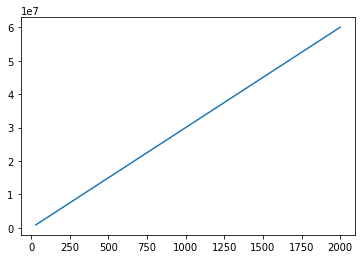

In [2]:
area_casa  = np.linspace(30, 2000, 100)
preco_casa = 30e3*area_casa + random.randrange(-2000, 2000)
plt.plot(area_casa, preco_casa)

In [3]:
model = tf.keras.Sequential([tf.keras.layers.Dense(units=1, input_shape=[1]) ])

In [4]:
print_weights = LambdaCallback(on_epoch_end=lambda batch, logs: print(model.layers[0].get_weights()))

In [5]:
model.compile(loss='mean_squared_error',
              optimizer=tf.keras.optimizers.Adam(0.01))

In [6]:
history = model.fit(area_casa, preco_casa, epochs=10000, verbose=False)

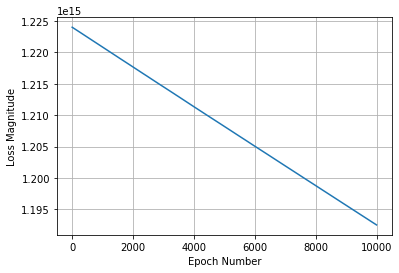

In [7]:
plt.xlabel('Epoch Number')
plt.ylabel("Loss Magnitude")
plt.plot(history.history['loss'])
plt.grid()

In [8]:
w, b = model.weights
print("Weights: \n {} \n Bias: \n {}".format(w,b))

Weights: 
 <tf.Variable 'dense/kernel:0' shape=(1, 1) dtype=float32, numpy=array([[389.71884]], dtype=float32)> 
 Bias: 
 <tf.Variable 'dense/bias:0' shape=(1,) dtype=float32, numpy=array([394.87427], dtype=float32)>


1/1 [==============================] - 0s 78ms/step


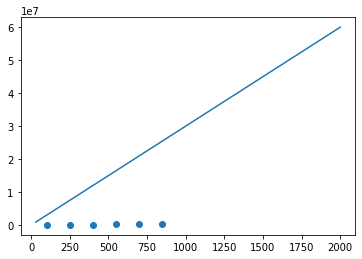

In [9]:
areas = np.arange(100, 1000, 150)
preco = model.predict(areas)
fig, ax = plt.subplots()
ax.scatter(areas, preco)
ax.plot(area_casa, preco_casa)